# 01 - Explatory Data Analysis

Goal: Understand the Telco Customer Churn dataset, identify data quality issues, and explore patterns that signal WHY customers leave.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style for all charts
sns.set_style("whitegrid")
# Load the raw dataset
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
# Check data types - notice TotalCharges is 'object' (string), not numeric
print(df.dtypes)
print(f"\nMissing values:\n{df.isnull().sum().sum()} total NaN values")

# The real issue: TotalCharges has blank strings instead of NaN
blanks = df[df["TotalCharges"] == " "]
print(f"\nRows with blank TotalCharges: {len(blanks)}")
blanks[["customerID", "tenure", "TotalCharges"]]

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values:
0 total NaN values

Rows with blank TotalCharges: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


## Data Quality Notes

- **TotalCharges** contains 11 blank strings (not NaN) for customers with 0 tenure.
- These will need conversion to numeric in the preprocessing step.
- No other missing values detected.

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn rate: 26.5%


/var/folders/0w/gg13m11j1rng3p821d52pbj00000gn/T/ipykernel_76400/3645725878.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", palette=["steelblue", "coral"])


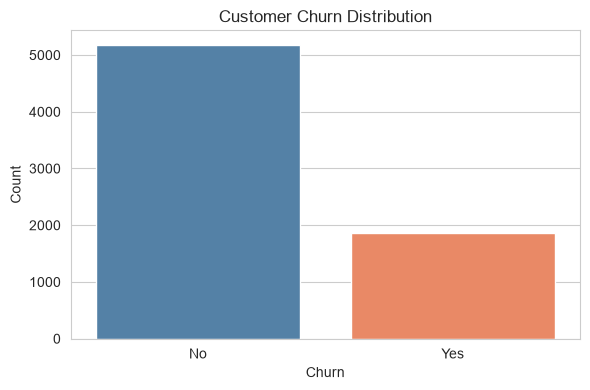

In [9]:
# Visualize target variable distribution (class imbalance check)
churn_counts = df["Churn"].value_counts()
print(churn_counts)
print(f"\nChurn rate: {churn_counts['Yes'] / len(df) * 100:.1f}%")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn", palette=["steelblue", "coral"])
plt.title("Customer Churn Distribution")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

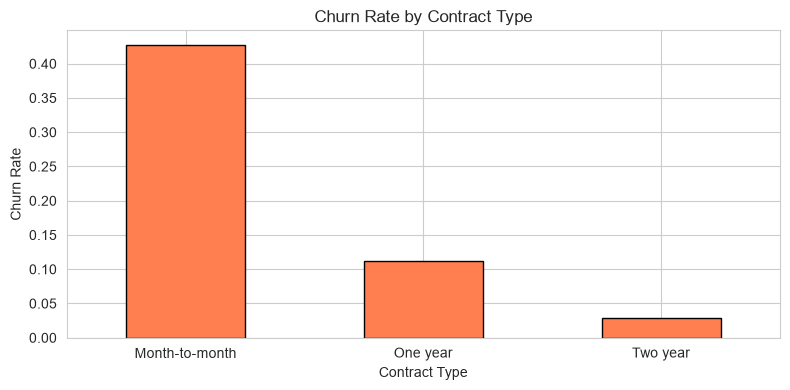

In [10]:
# Churn rate by contract type - month-to-month vs locked-in contracts
contract_churn = df.groupby("Contract")["Churn"].value_counts(normalize=True).unstack()

contract_churn["Yes"].plot(kind="bar", figsize=(8, 4), color="coral", edgecolor="black")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate")
plt.xlabel("Contract Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

/var/folders/0w/gg13m11j1rng3p821d52pbj00000gn/T/ipykernel_76400/647608771.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["steelblue", "coral"],


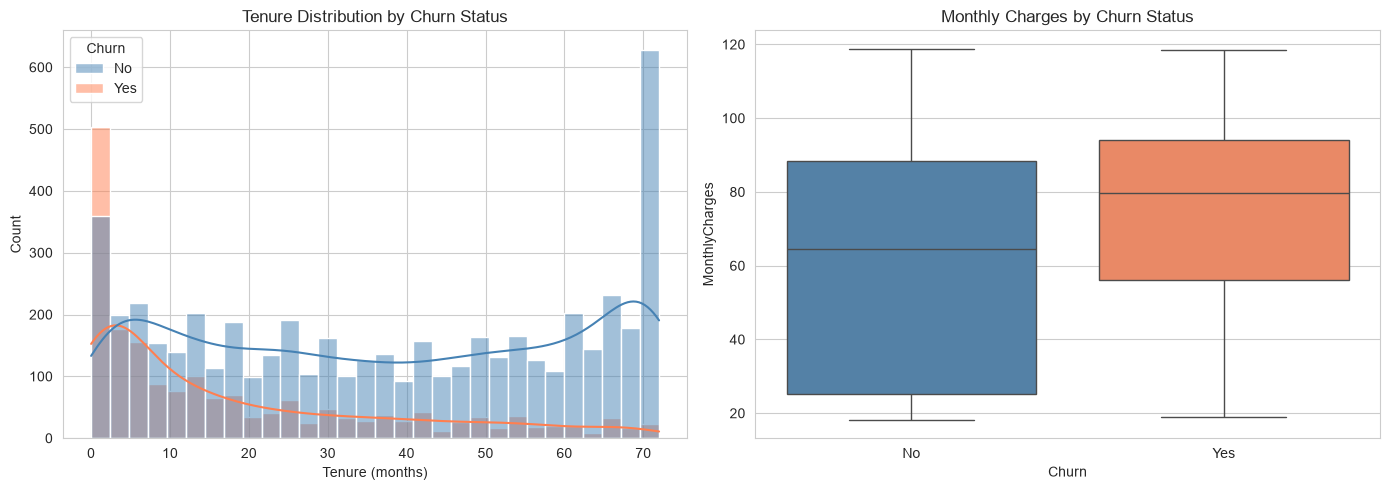

In [11]:
# Tenure distribution and monthly charges by churn status
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Tenure histogram split by churn
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[0],
             palette=["steelblue", "coral"])
axes[0].set_title("Tenure Distribution by Churn Status")
axes[0].set_xlabel("Tenure (months)")

# Right: Monthly charges boxplot split by churn
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["steelblue", "coral"],
            ax=axes[1])
axes[1].set_title("Monthly Charges by Churn Status")

plt.tight_layout()
plt.show()

## Key EDA Findings: Why Customers Leave

1. **Class imbalance**: ~27% churn rate means we need resampling or class weights during modeling.
2. **Contract type is a strong signal**: Month-to-month customers churn at 3-4x the rate of locked-in contracts.
3. **Tenure matters**: Most churn happens in the first 1-12 months. Long-tenure customers are loyal.
4. **Higher charges correlate with churn**: Customers paying more monthly are more likely to leave, possibly because they have more alternatives or feel less value.

**Business implication**: A retention team should target new, month-to-month customers with high monthly charges. These are the highest-risk group.